In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/sample_data/global-data-on-sustainable-energy (1).csv")

df.head()


,Entity,Year,Access to electricity (% of population),Access to clean fuels for cooking,Renewable-electricity-generating-capacity-per-capita,Financial flows to developing countries (US $),Renewable energy share in the total final energy consumption (%),Electricity from fossil fuels (TWh),Electricity from nuclear (TWh),Electricity from renewables (TWh),...,Primary energy consumption per capita (kWh/person),Energy intensity level of primary energy (MJ/$2017 PPP GDP),Value_co2_emissions_kt_by_country,Renewables (% equivalent primary energy),gdp_growth,gdp_per_capita,Density\n(P/Km2),Land Area(Km2),Latitude,Longitude
0,Afghanistan,2000,1.613591,6.2,9.22,20000.0,44.99,0.16,0.0,0.31,...,302.59482,1.64,760.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
1,Afghanistan,2001,4.074574,7.2,8.86,130000.0,45.60,0.09,0.0,0.50,...,236.89185,1.74,730.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
2,Afghanistan,2002,9.409158,8.2,8.47,3950000.0,37.83,0.13,0.0,0.56,...,210.86215,1.40,1029.999971,NaN,NaN,179.426579,60,652230.0,33.93911,67.709953
3,Afghanistan,2003,14.738506,9.5,8.09,25970000.0,36.66,0.31,0.0,0.63,...,229.96822,1.40,1220.000029,NaN,8.832278,190.683814,60,652230.0,33.93911,67.709953
4,Afghanistan,2004,20.064968,10.9,7.75,NaN,44.24,0.33,0.0,0.56,...,204.23125,1.20,1029.999971,NaN,1.414118,211.382074,60,652230.0,33.93911,67.709953


In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("/content/sample_data/global-data-on-sustainable-energy (1).csv")

# Display first rows
df.head()

,Entity,Year,Access to electricity (% of population),Access to clean fuels for cooking,Renewable-electricity-generating-capacity-per-capita,Financial flows to developing countries (US $),Renewable energy share in the total final energy consumption (%),Electricity from fossil fuels (TWh),Electricity from nuclear (TWh),Electricity from renewables (TWh),...,Primary energy consumption per capita (kWh/person),Energy intensity level of primary energy (MJ/$2017 PPP GDP),Value_co2_emissions_kt_by_country,Renewables (% equivalent primary energy),gdp_growth,gdp_per_capita,Density\n(P/Km2),Land Area(Km2),Latitude,Longitude
0,Afghanistan,2000,1.613591,6.2,9.22,20000.0,44.99,0.16,0.0,0.31,...,302.59482,1.64,760.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
1,Afghanistan,2001,4.074574,7.2,8.86,130000.0,45.60,0.09,0.0,0.50,...,236.89185,1.74,730.000000,NaN,NaN,NaN,60,652230.0,33.93911,67.709953
2,Afghanistan,2002,9.409158,8.2,8.47,3950000.0,37.83,0.13,0.0,0.56,...,210.86215,1.40,1029.999971,NaN,NaN,179.426579,60,652230.0,33.93911,67.709953
3,Afghanistan,2003,14.738506,9.5,8.09,25970000.0,36.66,0.31,0.0,0.63,...,229.96822,1.40,1220.000029,NaN,8.832278,190.683814,60,652230.0,33.93911,67.709953
4,Afghanistan,2004,20.064968,10.9,7.75,NaN,44.24,0.33,0.0,0.56,...,204.23125,1.20,1029.999971,NaN,1.414118,211.382074,60,652230.0,33.93911,67.709953


In [ ]:
# Dataset information
df.info()

# Check missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3649 entries, 0 to 3648
Data columns (total 21 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   Entity                                                            3649 non-null   object 
 1   Year                                                              3649 non-null   int64  
 2   Access to electricity (% of population)                           3639 non-null   float64
 3   Access to clean fuels for cooking                                 3480 non-null   float64
 4   Renewable-electricity-generating-capacity-per-capita              2718 non-null   float64
 5   Financial flows to developing countries (US $)                    1560 non-null   float64
 6   Renewable energy share in the total final energy consumption (%)  3455 non-null   float64
 7   Electricity from fossil fuels (TW

,0
Entity,0
Year,0
Access to electricity (% of population),10
Access to clean fuels for cooking,169
Renewable-electricity-generating-capacity-per-capita,931
Financial flows to developing countries (US $),2089
Renewable energy share in the total final energy consumption (%),194
Electricity from fossil fuels (TWh),21
Electricity from nuclear (TWh),126
Electricity from renewables (TWh),21


In [ ]:
# Select country
country = "United States"

# Select time series variable
ts = df[df["Entity"] == country][
    ["Year", "Renewable energy share in the total final energy consumption (%)"]
].copy()

# Rename column
ts.columns = ["Year", "Renewable_Energy_Share"]

# Remove missing values
ts = ts.dropna()

# Display result
ts.head()


,Year,Renewable_Energy_Share
3502,2000,5.43
3503,2001,4.68
3504,2002,4.84
3505,2003,5.33
3506,2004,5.48


            Renewable_Energy_Share
Year                              
2000-01-01                    5.43
2001-01-01                    4.68
2002-01-01                    4.84
2003-01-01                    5.33
2004-01-01                    5.48


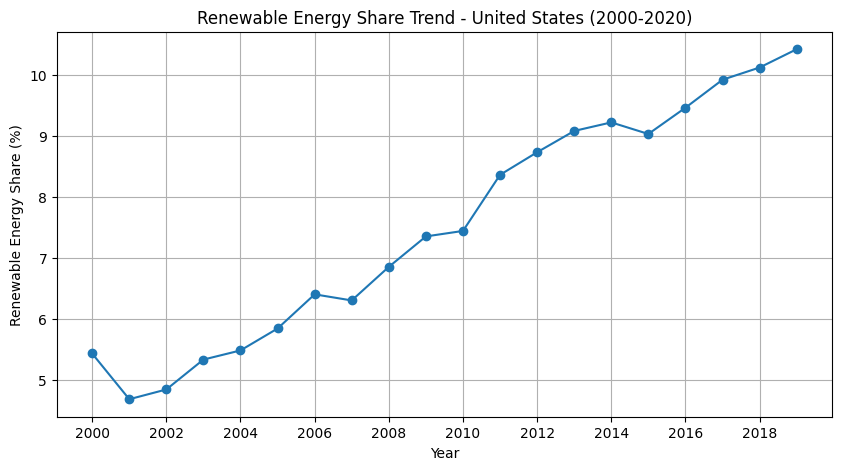

In [ ]:
import matplotlib.pyplot as plt

# Convert Year to datetime
ts["Year"] = pd.to_datetime(ts["Year"], format="%Y")

# Set Year as index
ts = ts.set_index("Year")

# Display data
print(ts.head())

# Plot trend
plt.figure(figsize=(10,5))
plt.plot(ts.index, ts["Renewable_Energy_Share"], marker="o")

plt.title("Renewable Energy Share Trend - United States (2000-2020)")
plt.xlabel("Year")
plt.ylabel("Renewable Energy Share (%)")
plt.grid()

plt.show()


In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test
result = adfuller(ts["Renewable_Energy_Share"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("The data is stationary")
else:
    print("The data is not stationary")


ADF Statistic: -0.46554288884036915
p-value: 0.8985669954247253
The data is not stationary


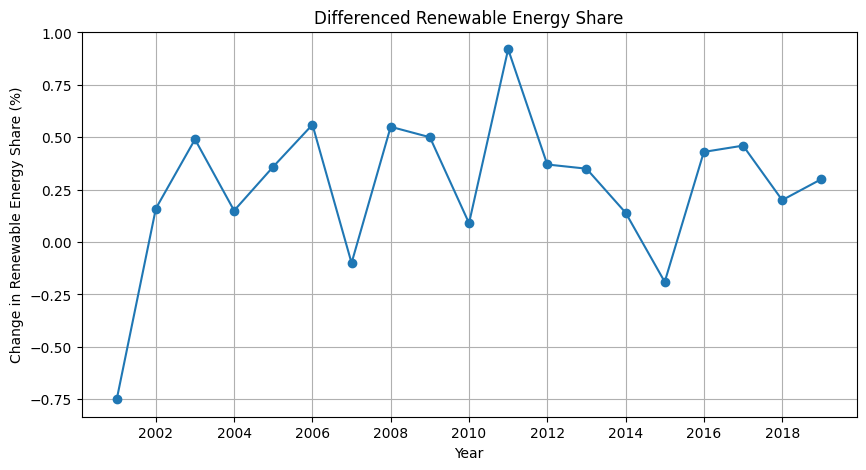

In [ ]:
# Apply first differencing
ts_diff = ts.diff().dropna()

# Plot differenced data
plt.figure(figsize=(10,5))
plt.plot(ts_diff.index, ts_diff["Renewable_Energy_Share"], marker="o")

plt.title("Differenced Renewable Energy Share")
plt.xlabel("Year")
plt.ylabel("Change in Renewable Energy Share (%)")
plt.grid()

plt.show()


In [ ]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(ts_diff["Renewable_Energy_Share"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("The data is now stationary")
else:
    print("The data is still not stationary")


ADF Statistic: -5.974961455645227
p-value: 1.897085044210303e-07
The data is now stationary


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Split data (80% train, 20% test)
train_size = int(len(ts) * 0.8)

train = ts[:train_size]
test = ts[train_size:]

# Build ARIMA model
model = ARIMA(train["Renewable_Energy_Share"], order=(1,1,1))

# Train model
model_fit = model.fit()

# Forecast
forecast = model_fit.forecast(steps=len(test))

# Display forecast
forecast


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA paramete

,predicted_mean
2016-01-01,9.072027
2017-01-01,9.106068
2018-01-01,9.133639
2019-01-01,9.155970


In [ ]:
# Create comparison dataframe
results = pd.DataFrame({
    "Actual": test["Renewable_Energy_Share"],
    "Forecast": forecast
})

results


,Actual,Forecast
2016-01-01,9.46,9.072027
2017-01-01,9.92,9.106068
2018-01-01,10.12,9.133639
2019-01-01,10.42,9.155970


In [ ]:
# Calculate evaluation metrics
mae = mean_absolute_error(results["Actual"], results["Forecast"])
rmse = np.sqrt(mean_squared_error(results["Actual"], results["Forecast"]))

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Absolute Error (MAE): 0.86307410914706
Root Mean Squared Error (RMSE): 0.9197403941246979


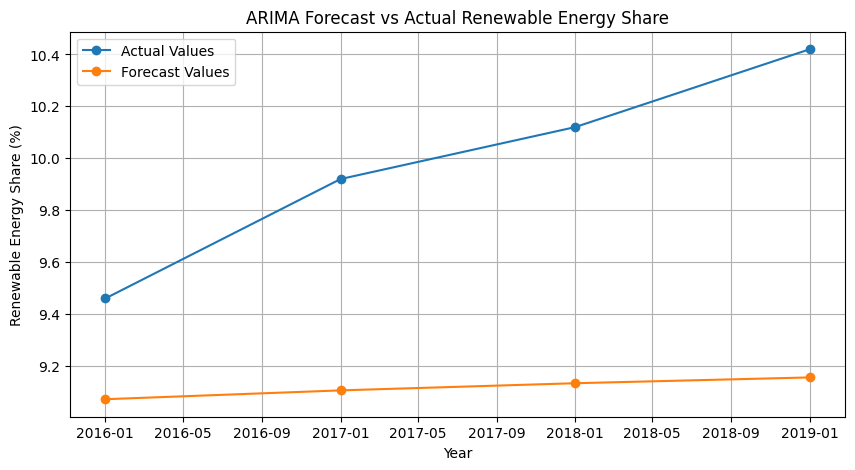

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(results.index, results["Actual"],
         marker="o", label="Actual Values")

plt.plot(results.index, results["Forecast"],
         marker="o", label="Forecast Values")

plt.title("ARIMA Forecast vs Actual Renewable Energy Share")
plt.xlabel("Year")
plt.ylabel("Renewable Energy Share (%)")

plt.legend()
plt.grid()

plt.show()


In [ ]:
# Conclusion:

# In this project, a time series forecasting model was developed to predict the renewable energy share in total final energy consumption using the Global Data on Sustainable Energy dataset (2000-2020).

# The dataset was cleaned and prepared by selecting yearly renewable energy data for the United States. Since the original time series was non-stationary, the Augmented Dickey-Fuller test was applied, and first-order differencing was performed to achieve stationarity.

# An ARIMA (AutoRegressive Integrated Moving Average) model was then trained on the historical data. The model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

# The model achieved:
# - MAE: 0.863
# - RMSE: 0.920

# The forecast values were close to the actual renewable energy share values, showing that ARIMA was able to capture the overall trend of renewable energy growth over time.

# This project demonstrates how time series analysis can be used to study energy trends and create forecasts that can support future planning and decision-making in the renewable energy sector.
